# Surf Maneuver Recognition: Data Exploration

Exploratory analysis of the Surf Maneuver Recognition dataset
([Hugging Face, `2nzi/surf-maneuvers`](https://huggingface.co/datasets/2nzi/surf-maneuvers)):
clip inventory, class balance and video properties.

## 1. Clip inventory

Each clip's label comes from its folder name: `data-split/<split>/<maneuver>/<clip>.mp4`.

In [5]:
from pathlib import Path
import pandas as pd

# The notebook lives in notebooks/, so the data folder is one level up
DATA_DIR = Path("..") / "data" / "raw" / "data-split"

rows = []
for video in sorted(DATA_DIR.glob("*/*/*.mp4")):
    split, maneuver = video.parts[-3], video.parts[-2]
    rows.append({"split": split, "maneuver": maneuver, "path": video})

df = pd.DataFrame(rows)
print(len(df), "clips")
df.head()

1062 clips


,split,maneuver,path
0,test,360,..\data\raw\data-split\test\360\360.mp4
1,test,360,..\data\raw\data-split\test\360\Séquence imbri...
2,test,360,..\data\raw\data-split\test\360\Séquence imbri...
3,test,360,..\data\raw\data-split\test\360\Séquence imbri...
4,test,360,..\data\raw\data-split\test\360\Séquence imbri...


## 2. Class balance

Number of clips per maneuver and split.

In [6]:
# Clips per maneuver and split; margins=True adds the row/column totals ("All")
pd.crosstab(df["maneuver"], df["split"], margins=True)

split,test,train,val,All
maneuver,,,,
360,36,125,19,180
cutback-frontside,47,166,25,238
roller,104,366,53,523
take-off,24,84,13,121
All,211,741,110,1062


## 3. Video metadata

Frame rate, frame count, resolution and duration, read from each file's header with OpenCV.

In [7]:
import cv2

def video_info(path):
    """Read video metadata from the file header (no frames are decoded)."""
    cap = cv2.VideoCapture(str(path))
    fps = cap.get(cv2.CAP_PROP_FPS)
    n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cap.release()
    return pd.Series({"fps": fps, "n_frames": n_frames, "width": width, "height": height})

# One row of metadata per clip, appended as new columns
info = df["path"].apply(video_info)
df = pd.concat([df, info], axis=1)

# Declared FPS can be wrong in some files, so durations are checked later
df["duration_s"] = df["n_frames"] / df["fps"]

# OpenCV fails silently (fps = 0) when it cannot open a file, e.g. some
# non-ASCII paths on Windows, so count those cases explicitly
print("unreadable videos:", (df["fps"] == 0).sum())
df.describe()

unreadable videos: 0


,fps,n_frames,width,height,duration_s
count,1062.000000,1062.000000,1062.0,1062.0,1062.000000
mean,29.614387,82.059322,640.0,360.0,2.773306
std,1.281702,39.405421,0.0,0.0,1.339273
min,25.000000,25.000000,640.0,360.0,0.834167
25%,29.970030,63.000000,640.0,360.0,2.135467
50%,29.970030,76.000000,640.0,360.0,2.569233
75%,29.970030,90.000000,640.0,360.0,3.040000
max,30.000000,464.000000,640.0,360.0,15.482133


## 4. Clip duration and outliers

Duration per maneuver, and the longest and shortest clips, to spot files that do not look like single-maneuver clips.

In [8]:
# Duration (seconds) per maneuver: are some maneuvers naturally longer?
df.groupby("maneuver")["duration_s"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
maneuver,,,,,,,,
360,180.0,3.07,1.02,1.17,2.60,2.87,3.27,9.54
cutback-frontside,238.0,3.19,0.88,1.57,2.74,3.10,3.47,9.04
roller,523.0,2.51,1.07,1.10,2.04,2.34,2.67,12.40
take-off,121.0,2.66,2.65,0.83,1.57,1.90,2.44,15.48


In [9]:
# The 5 longest and 5 shortest clips: candidates for odd files (e.g. "360.mp4")
df["file"] = df["path"].map(lambda p: p.name)
cols = ["file", "split", "maneuver", "n_frames", "fps", "duration_s"]
by_duration = df.sort_values("duration_s")

display(by_duration[cols].tail(5))
display(by_duration[cols].head(5))

,file,split,maneuver,n_frames,fps,duration_s
86,Roller_29.mp4,test,roller,310.0,25.00000,12.400000
204,Séquence_imbriquée_167.mp4,test,take-off,395.0,29.97003,13.179833
1057,Séquence_imbriquée_163.mp4,val,take-off,407.0,29.97003,13.580233
933,Séquence_imbriquée_165.mp4,train,take-off,437.0,29.97003,14.581233
935,Séquence_imbriquée_168.mp4,train,take-off,464.0,29.97003,15.482133


,file,split,maneuver,n_frames,fps,duration_s
898,Séquence imbriquée 510.mp4,train,take-off,25.0,29.97003,0.834167
881,Séquence imbriquée 1159.mp4,train,take-off,32.0,29.97003,1.067733
654,Séquence imbriquée 551.mp4,train,roller,33.0,29.97003,1.101100
327,Séquence_imbriquée_429.mp4,train,360,35.0,29.97003,1.167833
918,Séquence imbriquée 965.mp4,train,take-off,36.0,29.97003,1.201200


## 5. File naming patterns

File names follow different patterns (`Séquence imbriquée N`, `Séquence_imbriquée_N`, and others such as `Roller_29.mp4`).
Different patterns may indicate different sources or editing batches, which matters for class balance and for possible leakage between splits.

In [10]:
def name_pattern(name):
    """Group file names by naming convention (a proxy for the clip's source)."""
    if "imbriqu" in name:
        return "sequence_underscore" if "_" in name else "sequence_space"
    return "other"

df["name_pattern"] = df["file"].map(name_pattern)

# How each naming pattern is spread across maneuvers and splits
pd.crosstab(df["name_pattern"], [df["maneuver"], df["split"]], margins=True)

maneuver             360           cutback-frontside           roller        \
split               test train val              test train val   test train   
name_pattern                                                                  
other                  1     3   0                 0     0   0      6    37   
sequence_space        21    66  11                22    77  12     75   235   
sequence_underscore   14    56   8                25    89  13     23    94   
All                   36   125  19                47   166  25    104   366   

maneuver                take-off             All  
split               val     test train val        
name_pattern                                      
other                 2        0     0   0    49  
sequence_space       37       14    56   8   634  
sequence_underscore  14       10    28   5   379  
All                  53       24    84  13  1062

In [12]:
# Files outside the two "Séquence" patterns, summarized by maneuver and split
other = df[df["name_pattern"] == "other"]
other.groupby(["maneuver", "split"]).agg(
    n_clips=("file", "size"),
    fps=("fps", "unique"),
    examples=("file", lambda s: ", ".join(s.head(3))),
)

n_clips     fps                                     examples
maneuver split                                                              
360      test         1  [30.0]                                      360.mp4
         train        3  [25.0]              360_0.mp4, 360_1.mp4, 360_2.mp4
roller   test         6  [25.0]  Roller_16.mp4, Roller_17.mp4, Roller_25.mp4
         train       37  [25.0]       Roller.mp4, Roller_0.mp4, Roller_1.mp4
         val          2  [25.0]                 Roller_20.mp4, Roller_38.mp4

## 6. Possible leakage between splits

Clips with near-consecutive numbers in the same source were probably cut from the same footage (same wave or session).
If such neighbors fall into different splits, the test set contains near-duplicates of training clips and test metrics will be optimistic.
Here we count how often neighboring clips end up in different splits. This is evidence, not proof; the visual check in the next section confirms it.

In [13]:
import re

# Source of each clip: the naming pattern, or the file prefix for "other" files
# (e.g. "Roller_29.mp4" -> "roller", "360_1.mp4" -> "360")
df["source"] = df["name_pattern"].where(
    df["name_pattern"] != "other",
    df["file"].str.split(r"[_.]", regex=True).str[0].str.lower(),
)

def clip_number(name):
    """Trailing clip number after a space or underscore; None if absent (e.g. "360.mp4")."""
    match = re.search(r"[ _](\d+)\.mp4$", name)
    return int(match.group(1)) if match else None

df["clip_number"] = df["file"].map(clip_number)
df[["file", "source", "clip_number"]].sample(5, random_state=0)

,file,source,clip_number
418,Séquence_imbriquée_11.mp4,sequence_underscore,11.0
202,Séquence_imbriquée_113.mp4,sequence_underscore,113.0
683,Séquence imbriquée 630.mp4,sequence_space,630.0
316,Séquence_imbriquée_326.mp4,sequence_underscore,326.0
267,Séquence imbriquée 977.mp4,sequence_space,977.0


In [14]:
# Pair each clip with the next clip (by number) from the same source
neighbors = df.dropna(subset=["clip_number"]).sort_values(["source", "clip_number"]).copy()
neighbors["next_number"] = neighbors.groupby("source")["clip_number"].shift(-1)
neighbors["next_split"] = neighbors.groupby("source")["split"].shift(-1)

# Keep only near-consecutive pairs (number gap of at most 2)
close = neighbors[(neighbors["next_number"] - neighbors["clip_number"]) <= 2]

cross_split = (close["split"] != close["next_split"]).mean()
print(f"{len(close)} near-consecutive pairs; {cross_split:.0%} fall into different splits")
pd.crosstab(close["split"], close["next_split"], rownames=["clip"], colnames=["next clip"])

1001 near-consecutive pairs; 46% fall into different splits


next clip,test,train,val
clip,,,
test,43,140,16
train,133,486,78
val,23,72,10


In [15]:
# Do neighbors share the maneuver? If numbering were one global editing order
# mixing all maneuvers, neighbors would often have different labels
neighbors["next_maneuver"] = neighbors.groupby("source")["maneuver"].shift(-1)
close = neighbors[(neighbors["next_number"] - neighbors["clip_number"]) <= 2]
print(f"{(close['maneuver'] == close['next_maneuver']).mean():.0%} of near-consecutive pairs share the maneuver")

54% of near-consecutive pairs share the maneuver


## 7. Visual check of neighboring clips

The middle frame of clips with consecutive numbers, side by side.
Same sea, light and surfer across splits would confirm that the original split leaks footage between train and test.

In [18]:
import matplotlib.pyplot as plt

def middle_frame(path):
    """Return the middle frame of a clip as an RGB array (OpenCV reads BGR)."""
    cap = cv2.VideoCapture(str(path))
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) // 2)
    ok, frame = cap.read()
    cap.release()
    return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB) if ok else None

def show_clips(source, numbers, title):
    """Show the middle frame of the given clips from one source, with split and maneuver."""
    clips = df[(df["source"] == source) & df["clip_number"].isin(numbers)].sort_values("clip_number")
    fig, axes = plt.subplots(1, len(clips), figsize=(4 * len(clips), 3), squeeze=False)
    for ax, (_, clip) in zip(axes[0], clips.iterrows()):
        ax.imshow(middle_frame(clip["path"]))
        ax.set_title(f"{clip['file']}\n{clip['split']} | {clip['maneuver']}", fontsize=9)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

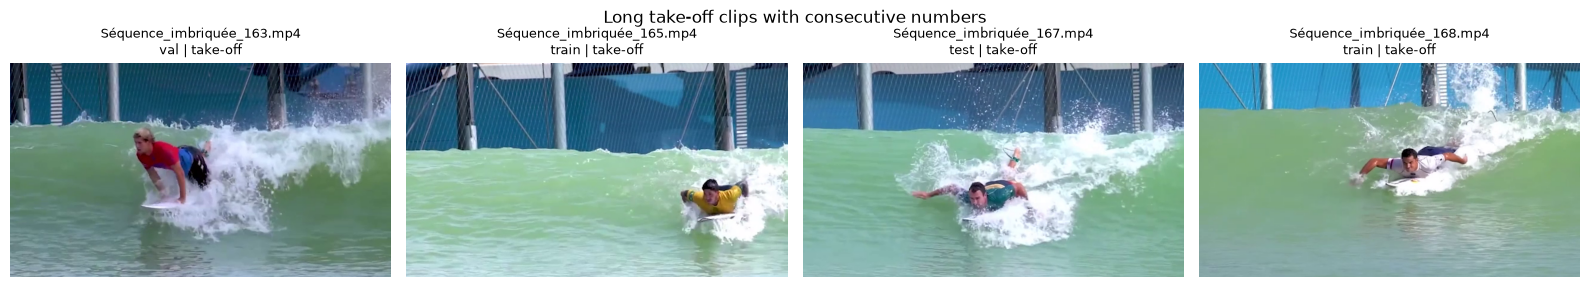

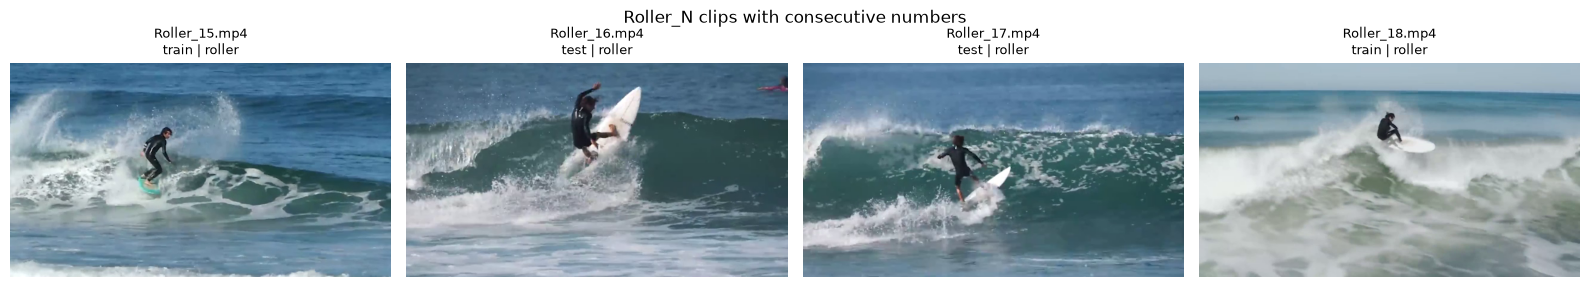

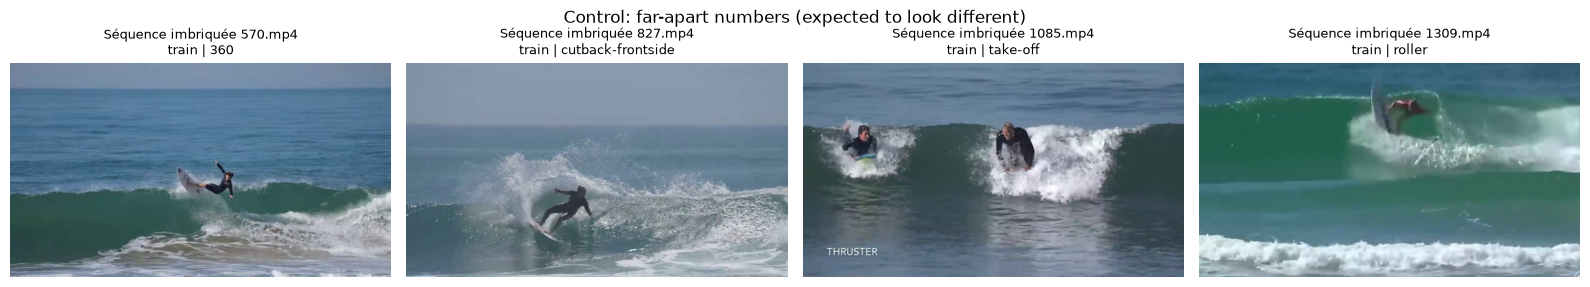

In [20]:
show_clips("sequence_underscore", [163, 165, 167, 168], "Long take-off clips with consecutive numbers")
show_clips("roller", [15, 16, 17, 18], "Roller_N clips with consecutive numbers")

# Control: existing clip numbers spread across the numbering (10th to 95th percentile)
space_numbers = df.loc[df["source"] == "sequence_space", "clip_number"].dropna()
control = space_numbers.quantile([0.10, 0.40, 0.70, 0.95], interpolation="nearest").astype(int).tolist()
show_clips("sequence_space", control, "Control: far-apart numbers (expected to look different)")

## 8. Findings

1. **Class imbalance.** Roller has 523 clips and take-off only 121 (4.3x). Accuracy alone would be misleading, so we report macro F1 and per-class F1.
2. **Uniform resolution, mixed frame rates.** All clips are 640x360; frame rates are 25 or 29.97 fps. Every clip has at least 25 frames, enough for 16-frame models.
3. **The default center crop discards half of the frame.** Resizing the short side to 292 px and cropping 256x256 keeps only the central part of a 640x360 clip, so an off-center surfer can be cut out. This motivates cropping around the detected surfer.
4. **Noisy labels.** The four longest clips (13–15 s) are labeled take-off, a maneuver that lasts 1–2 s, so they likely contain paddling or the whole ride.
5. **Multiple sources.** Besides the two "Séquence imbriquée" patterns, 45 roller clips (`Roller_N`) come from a separate 25 fps source. A model could learn the source's look instead of the motion.
6. **Session-level leakage in the original split.** Clips with consecutive numbers come from the same session (same surfer, spot and camera), while far-apart numbers look different. Neighboring clips fall into different splits at the rate expected from a random clip-level split (46%), so test clips share sessions with training clips.
7. **Other shortcuts to watch.** Some clips show more than one surfer, and some carry watermarks.

**Next steps:** build a session-grouped split (`data/splits.csv`) and compare models on both the original and the grouped split.